# Empirical-score probability flow: a one-dimensional mixture

**Draft worked experiment. No neural network is trained.** We derive and evaluate the exact score of a corrupted empirical distribution. We test two distinct statements: (i) its denoiser is a softmax-weighted interpolation; (ii) its reverse ODE need not output a training observation at a positive stopping time. Neither statement establishes that the zero-noise output law is a continuous interpolating distribution.

[Part 07 · Empirical-score sampling](../../../tutorials/41-empirical-score-interpolation.html). The VP probability-flow construction follows [Song et al.](https://arxiv.org/abs/2011.13456). Requirements: NumPy, SciPy, Matplotlib, threadpoolctl and Jupyter. Run all cells in order on a CPU.

## 1. Empirical data and its exact Gaussian-mixture score

For observed scalars $x_1,\ldots,x_n$, $\widehat P_0=n^{-1}\sum_i\delta_{x_i}$. Under $X_t=\alpha_tX_0+\sigma_t\varepsilon$,
$$\widehat p_t(x)=\frac1n\sum_i\mathcal N(x;\alpha_tx_i,\sigma_t^2),\quad
w_i(x,t)=\operatorname{softmax}_i\left(-\frac{(x-\alpha_tx_i)^2}{2\sigma_t^2}\right).$$
Consequently,
$$m_t(x)=\sum_iw_i(x,t)x_i,\qquad s_t(x)=\frac{\alpha_tm_t(x)-x}{\sigma_t^2},\qquad
v(x,t)=\frac{\beta(t)\alpha_t}{2\sigma_t^2}(\alpha_tx-m_t(x)).$$
Use $\beta(t)=0.1+19.9t$, $\alpha_t=\exp(-0.05t-4.975t^2)$ and $\sigma_t^2=1-\alpha_t^2$. All calculations stop at positive time.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import softmax
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=2)
np.set_printoptions(precision=5, suppress=True)

def schedule(t):
    beta = 0.1 + 19.9*t
    a = np.exp(-0.05*t - 4.975*t*t)
    s2 = -np.expm1(-0.1*t - 9.95*t*t)
    return a, s2, beta

def posterior(x, t, data, topk=None):
    # x: (batch, dimension), data: (observations, dimension).
    a, s2, _ = schedule(t)
    # Drop the common -||x||^2/(2*s2) term for numerical stability.
    logits = (a*(x @ data.T) - 0.5*a*a*np.sum(data*data, axis=1))/s2
    if topk is not None and topk < len(data):
        ix = np.argpartition(logits, -topk, axis=1)[:, -topk:]
        mask = np.full_like(logits, -np.inf)
        np.put_along_axis(mask, ix, np.take_along_axis(logits, ix, axis=1), axis=1)
        logits = mask
    w = softmax(logits, axis=1)
    return w @ data, w

def velocity(x, t, data, topk=None):
    a, s2, beta = schedule(t)
    m, _ = posterior(x, t, data, topk)
    return beta*a/(2*s2)*(a*x-m)

def integrate(x1, data, steps=600, stops=(0.8,0.6,0.4,0.2,0.1,0.03,0.01), topk=None):
    # Nonuniform times resolve small-noise behavior. No clipping of particles.
    times = np.unique(np.r_[np.geomspace(min(stops), 1., steps+1), stops])[::-1]
    x = np.array(x1, dtype=np.float64, copy=True)
    saved = {1.: x.copy()}
    stopset = set(stops)
    for t, u in zip(times[:-1], times[1:]):
        x += (u-t)*velocity(x, t, data, topk)
        if u in stopset:
            saved[float(u)] = x.copy()
    return saved

def nearest(x, data):
    d2 = np.maximum(np.sum(x*x,1)[:,None] + np.sum(data*data,1)[None,:] - 2*x@data.T, 0)
    ix = np.argmin(d2, axis=1)
    return ix, np.sqrt(d2[np.arange(len(x)),ix]/data.shape[1])

def diagnostics(x, t, data):
    m, w = posterior(x,t,data)
    _, raw_rmse = nearest(x,data)
    _, mean_rmse = nearest(m,data)
    return [raw_rmse.mean(), mean_rmse.mean(), np.mean(1/np.sum(w*w,axis=1)), np.mean(w.max(1))]


## 2. Separate the population mixture from its finite dataset

Draw $n=128$ observations from $\frac12\mathcal N(-2,0.25)+\frac12\mathcal N(2,0.25)$. This population density is continuous. Its empirical distribution is discrete. Our sampler uses the latter, not the analytic population score. Plot both scores to see the distinction.

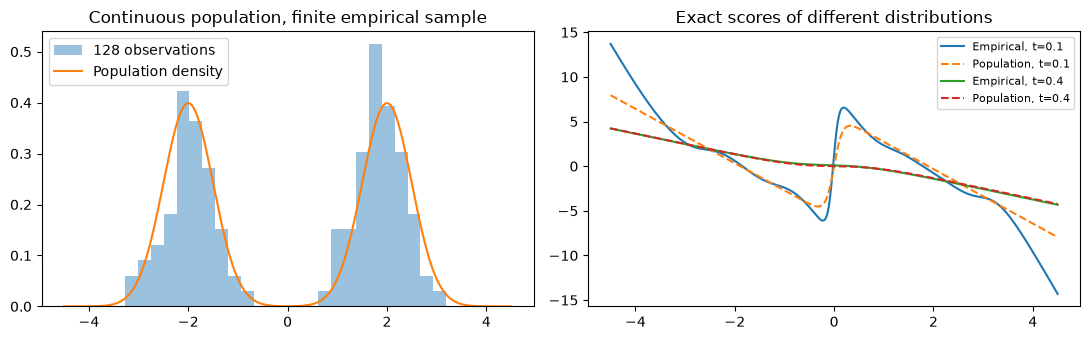

Score finite-difference maximum error: 1.0680822892794595e-10


In [2]:
from scipy.stats import norm, wasserstein_distance
rng = np.random.default_rng(20261014)
data = (rng.choice([-2.,2.],128) + 0.5*rng.normal(size=128))[:,None]
grid = np.linspace(-4.5,4.5,700)[:,None]
fig, ax = plt.subplots(1,2,figsize=(11,3.5))
ax[0].hist(data[:,0],bins=25,density=True,alpha=.45,label='128 observations')
ax[0].plot(grid[:,0], .5*norm.pdf(grid[:,0],-2,.5)+.5*norm.pdf(grid[:,0],2,.5),label='Population density')
ax[0].legend(); ax[0].set_title('Continuous population, finite empirical sample')
for t in [.1,.4]:
    a,s2,_=schedule(t)
    m,_=posterior(grid,t,data)
    empirical=(a*m-grid)/s2
    var=a*a*.25+s2
    logits=np.column_stack([-(grid[:,0]+2*a)**2/(2*var),-(grid[:,0]-2*a)**2/(2*var)])
    popmean=softmax(logits,axis=1)@np.array([-2*a,2*a])
    ax[1].plot(grid[:,0],empirical[:,0],label=f'Empirical, t={t}')
    ax[1].plot(grid[:,0],(popmean-grid[:,0])/var,'--',label=f'Population, t={t}')
ax[1].legend(fontsize=8); ax[1].set_title('Exact scores of different distributions')
plt.tight_layout(); plt.show()
# Independent finite-difference check of the empirical log-density derivative.
from scipy.special import logsumexp
def logdensity(x,t):
    a,s2,_=schedule(t)
    return logsumexp(-(x[:,None]-a*data[:,0])**2/(2*s2),axis=1)-np.log(len(data))-.5*np.log(2*np.pi*s2)
xcheck=np.linspace(-3,3,21); t=.3; delta=1e-5
a,s2,_=schedule(t)
m,_=posterior(xcheck[:,None],t,data)
error=np.max(np.abs((logdensity(xcheck+delta,t)-logdensity(xcheck-delta,t))/(2*delta)-(a*m[:,0]-xcheck)/s2))
assert error<1e-6
print('Score finite-difference maximum error:',error)

## 3. Fresh terminal samples and backward-time Euler

Compare a fresh draw from the exact empirical terminal mixture with an independent standard-normal initialization. Neither uses a recorded deterministic forward trajectory. The Gaussian prior is only approximate because $\alpha_1>0$. Euler updates $x_u=x_t+(u-t)v(x_t,t)$ with $u<t$.

At each cutoff report the distance to the nearest stored observation for both the raw ODE state and the posterior-mean output. The effective number of contributing observations is $1/\sum_iw_i^2$. A nonzero distance at positive time is not evidence about the singular zero-time limit.

time   raw nearest | denoised nearest | effective count | max weight (means)
0.600 [  0.26278   0.37295 118.14376   0.01102]
0.300 [ 0.1378   0.04775 67.28394  0.02308]
0.100 [ 0.02333  0.01183 36.32926  0.05682]
0.030 [ 0.01319  0.01174 14.88902  0.1385 ]
0.010 [0.01115 0.00852 6.65709 0.27902]
0.003 [0.00814 0.00528 3.31562 0.47466]
0.001 [0.00591 0.00302 2.11809 0.64522]
W1 to direct positive-time mixture, t= 0.3 matched: 0.02971133277429106 normal: 0.029797943323024934
W1 to direct positive-time mixture, t= 0.01 matched: 0.042489482013624125 normal: 0.042453903029163034


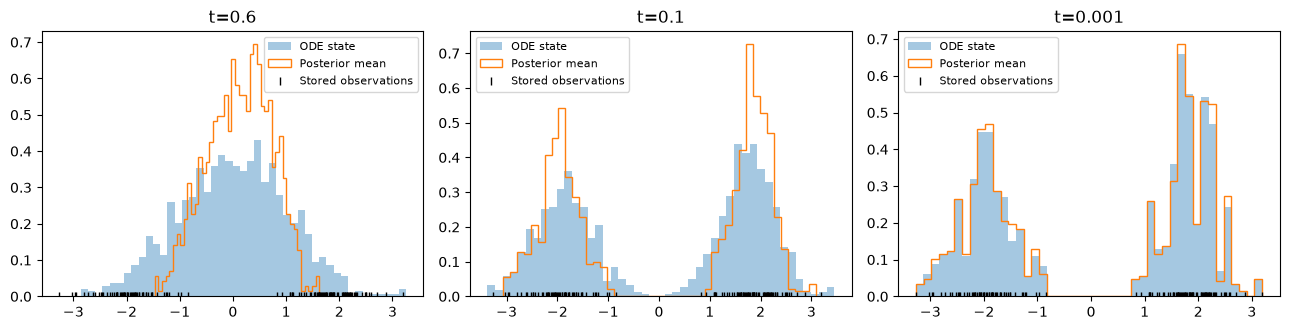

In [3]:
a1,s21,_=schedule(1.)
z=rng.normal(size=(1024,1))
exact_init=a1*data[rng.integers(len(data),size=len(z))]+np.sqrt(s21)*z
normal_init=z.copy()
stops=(.6,.3,.1,.03,.01,.003,.001)
paths=integrate(exact_init,data,800,stops)
normal_paths=integrate(normal_init,data,800,stops)
print('time   raw nearest | denoised nearest | effective count | max weight (means)')
for t in stops:
    print(f'{t:5.3f}',np.array(diagnostics(paths[t],t,data)))
# Monte Carlo check against direct sampling of the known positive-time mixture.
for t in [.3,.01]:
    a,s2,_=schedule(t)
    direct=a*data[rng.integers(len(data),size=10000),0]+np.sqrt(s2)*rng.normal(size=10000)
    print('W1 to direct positive-time mixture, t=',t,
          'matched:',wasserstein_distance(paths[t][:,0],direct),
          'normal:',wasserstein_distance(normal_paths[t][:,0],direct))
fig,ax=plt.subplots(1,3,figsize=(13,3.4))
for panel,t in zip(ax,[.6,.1,.001]):
    x=paths[t]; m,w=posterior(x,t,data)
    panel.hist(x[:,0],bins=45,density=True,alpha=.4,label='ODE state')
    panel.hist(m[:,0],bins=45,density=True,histtype='step',label='Posterior mean')
    panel.plot(data[:,0],np.zeros(len(data)),'|',color='black',label='Stored observations')
    panel.set_title(f't={t}'); panel.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. How posterior weights change along one trajectory

Choose the first freshly generated particle and hold its identity fixed as time decreases. At each cutoff, compute all $n=128$ posterior probabilities $w_i(x_t,t)$. The heatmap orders columns by the **clean observation** $x_i$, so it shows which stored observations support that particle. The red dot is $m_t(x_t)$ on the clean-data scale. The colorbar gives the posterior probability scale; the right panel plots the effective support count $N_{\rm eff}=1/\sum_iw_i^2$ and compares it with $n$. At $t=1$, weights are close to $1/n$ but not exactly uniform because $\alpha_1>0$.

A posterior mean between observations is an interpolation. A low-noise weight vector concentrated on one observation describes near-retrieval instead. These plots track the denoiser's posterior, not the probability assigned to an ODE path.
The heatmap clamps very small weights to its darkest color; the computed weights and printed diagnostics are unchanged.

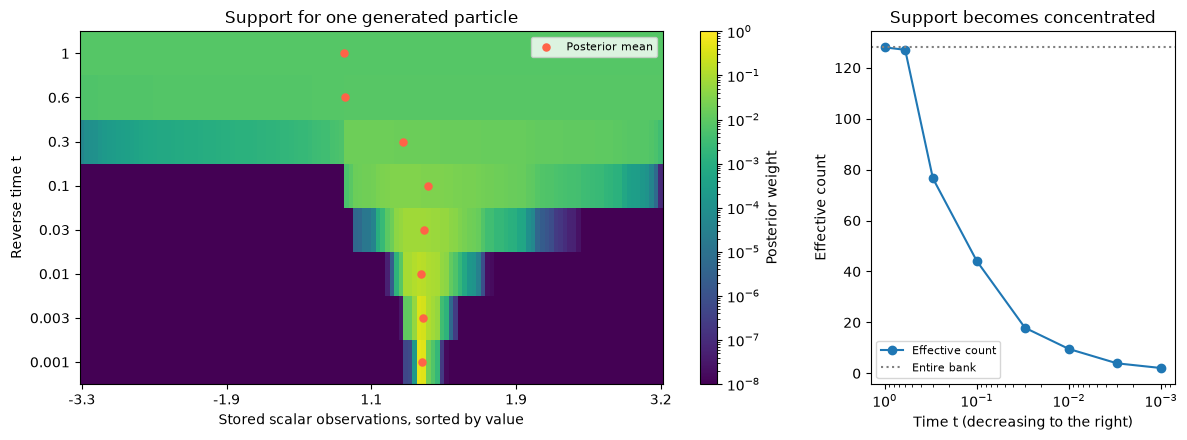

t | effective count | largest weight | top-three bank indices and their clean values
1.000 |  127.999 |  0.0078 | [(103, 3.189), (71, 2.878), (23, 2.708)]
0.600 |  127.040 |  0.0084 | [(26, 1.534), (74, 1.534), (9, 1.547)]
0.300 |   76.575 |  0.0176 | [(80, 0.93), (76, 1.077), (37, 1.082)]
0.100 |   44.096 |  0.0316 | [(119, 1.473), (1, 1.444), (74, 1.534)]
0.030 |   17.901 |  0.0749 | [(9, 1.547), (121, 1.584), (26, 1.534)]
0.010 |    9.581 |  0.1490 | [(121, 1.584), (39, 1.597), (9, 1.547)]
0.003 |    3.942 |  0.3627 | [(121, 1.584), (39, 1.597), (6, 1.617)]
0.001 |    2.103 |  0.5231 | [(121, 1.584), (39, 1.597), (6, 1.617)]


In [4]:
times=[1.,.6,.3,.1,.03,.01,.003,.001]
order=np.argsort(data[:,0])
weight_rows=[]; means=[]; neff=[]; maxw=[]
for t in times:
    m,w=posterior(paths[t][:1],t,data)
    weight_rows.append(w[0,order])
    means.append(m[0,0])
    neff.append(1/np.sum(w[0]**2))
    maxw.append(np.max(w[0]))
weights=np.stack(weight_rows)
fig,(ax,ax2)=plt.subplots(1,2,figsize=(12,4.5),gridspec_kw={'width_ratios':[2.4,1]})
im=ax.imshow(np.maximum(weights,1e-12),aspect='auto',cmap='viridis',norm=plt.matplotlib.colors.LogNorm(vmin=1e-8,vmax=1),interpolation='nearest')
ax.scatter([np.interp(m,data[order,0],np.arange(len(data))) for m in means],np.arange(len(times)),color='tomato',s=26,label='Posterior mean')
ax.set_yticks(range(len(times)),[f'{t:g}' for t in times]);ax.set_ylabel('Reverse time t')
ax.set_xticks(np.linspace(0,len(data)-1,5),[f'{v:.1f}' for v in np.quantile(data[:,0],[0,.25,.5,.75,1])]);ax.set_xlabel('Stored scalar observations, sorted by value')
ax.set_title('Support for one generated particle');ax.legend(loc='upper right',fontsize=8)
fig.colorbar(im,ax=ax,label='Posterior weight')
ax2.plot(times,neff,'o-',label='Effective count')
ax2.axhline(len(data),ls=':',color='gray',label='Entire bank')
ax2.set_xscale('log');ax2.invert_xaxis();ax2.set_xlabel('Time t (decreasing to the right)');ax2.set_ylabel('Effective count')
ax2.set_title('Support becomes concentrated');ax2.legend(fontsize=8)
plt.tight_layout();plt.show()
print('t | effective count | largest weight | top-three bank indices and their clean values')
for t,w,count,largest in zip(times,weight_rows,neff,maxw):
    top=np.argsort(w)[-3:][::-1]
    original_indices=order[top]
    print(f'{t:5.3f} | {count:8.3f} | {largest:7.4f} |',[(int(i),round(float(data[i,0]),3)) for i in original_indices])

## 5. Step refinement and truncated responsibilities

At the same terminal points compare two step counts to identify numerical error. Top-$k$ responsibilities are renormalized after retaining the largest logits. This implementation still calculates every logit: it tests approximation error, not nearest-neighbor acceleration. An actual accelerated implementation needs a search/index strategy and a control on omitted posterior mass.

In [5]:
fine=integrate(exact_init[:128],data,1600,stops)
print('Paired Euler mean absolute differences (800 vs 1600):')
for t in [.3,.01,.001]:
    print(t,float(np.mean(np.abs(paths[t][:128]-fine[t]))))
for t in [.6,.1,.01]:
    x=paths[t][:128]; m,w=posterior(x,t,data)
    mk,_=posterior(x,t,data,topk=8)
    retained=np.sort(w,axis=1)[:,-8:].sum(1)
    print('t, retained mass, denoiser MAE:',t,retained.mean(),np.mean(np.abs(m-mk)))
# A special initial point need not approach a training atom: symmetry fixes zero.
symmetric=np.array([[-1.],[1.]])
fixed=integrate(np.array([[0.]]),symmetric,500,(.1,.01,.001))
assert np.allclose(fixed[.001],0)
print('Symmetry-fixed path at t=.001:',fixed[.001].ravel())

Paired Euler mean absolute differences (800 vs 1600):
0.3 0.0032925279532184503
0.01 0.0017557540526381447
0.001 0.0018033608122506057
t, retained mass, denoiser MAE: 0.6 0.08500197746657598 1.949856985898958
t, retained mass, denoiser MAE: 0.1 0.3416691767355 0.09967571689625171
t, retained mass, denoiser MAE: 0.01 0.9233654984365028 0.001719752004038822
Symmetry-fixed path at t=.001: [0.]


## 6. What the experiment establishes

No network is needed to evaluate this empirical score or integrate its field. Positive-noise posterior means interpolate training values, and positive-time ODE states generally differ from stored observations. The exceptional symmetry-fixed path stays at zero for the two-atom example, although a continuous terminal law assigns that precise point probability zero.

For the exact terminal law, the exact ODE marginals at positive time are the empirical Gaussian mixtures and converge weakly to the empirical point masses as noise vanishes. Finite cutoff, denoising, approximate initialization, numerical error and truncated weights are distinct modifications. None should be silently identified with sampling the empirical endpoint law. A single path's exception also does not establish a non-atomic output distribution.

For interpolation as an intentional output rule, use $m_\epsilon(X_\epsilon)$ at a chosen positive cutoff, and evaluate that new output law on its own terms. At very low noise, interpolation can become numerically indistinguishable from selecting one stored value.

**Saved-run observations.** At $t=0.6$, the mean effective count was 118.14 out of 128; at $t=0.001$ it was 2.12. The mean distance between the denoised output and its nearest stored scalar decreased from 0.373 to 0.00302. Thus the finite-cutoff outputs interpolate, while their weights become more concentrated as noise decreases. The independent finite-difference score check had maximum error $1.07\times10^{-10}$. The paired Euler difference at the lowest cutoff was about 0.00180, so the reported finite-step locations are not exact ODE solutions.